## Title: Heart Disease Prediction
Author: Muhammad Talha Imran\
[Linkedin](https://www.linkedin.com/in/talha-imran-ai)\
[Github](https://github.com/mtalhaimran104)\
Date: 10.Oct.2026

### Import Libraries
Let's start importing libraries used in project

In [24]:
# import libraries

# To handle the data
import pandas as pd
import numpy as np

# To visualize the dataset
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from plotly.express import scatter

# To preprocess the data
from sklearn.preprocessing import StandardScaler, MinMaxScaler, LabelEncoder
from sklearn.impute import SimpleImputer, KNNImputer

# import iterative imputer
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer

# Machine Learning
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score

# For classification task
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier, ExtraTreesClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# import warnings
import warnings
warnings.filterwarnings('ignore')

### Load the dataset

In [25]:
# Load dataset
df = pd.read_csv('dataset/heart_disease_uci.csv')
df.head()

,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0


### Exploratory Data Analysis (EDA)

In [26]:
# exploring the datatype of each column
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 920 entries, 0 to 919
Data columns (total 16 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        920 non-null    int64  
 1   age       920 non-null    int64  
 2   sex       920 non-null    str    
 3   dataset   920 non-null    str    
 4   cp        920 non-null    str    
 5   trestbps  861 non-null    float64
 6   chol      890 non-null    float64
 7   fbs       830 non-null    object 
 8   restecg   918 non-null    str    
 9   thalch    865 non-null    float64
 10  exang     865 non-null    object 
 11  oldpeak   858 non-null    float64
 12  slope     611 non-null    str    
 13  ca        309 non-null    float64
 14  thal      434 non-null    str    
 15  num       920 non-null    int64  
dtypes: float64(5), int64(3), object(2), str(6)
memory usage: 115.1+ KB


In [27]:
# data shape
df.shape

(920, 16)

In [28]:
# id column
df['id'].min(), df['id'].max()

(np.int64(1), np.int64(920))

In [29]:
# age column
df['age'].min(), df['age'].max()

(np.int64(28), np.int64(77))

In [30]:
# summarize the age column
df['age'].describe()

count    920.000000
mean      53.510870
std        9.424685
min       28.000000
25%       47.000000
50%       54.000000
75%       60.000000
max       77.000000
Name: age, dtype: float64

<Axes: xlabel='age', ylabel='Count'>

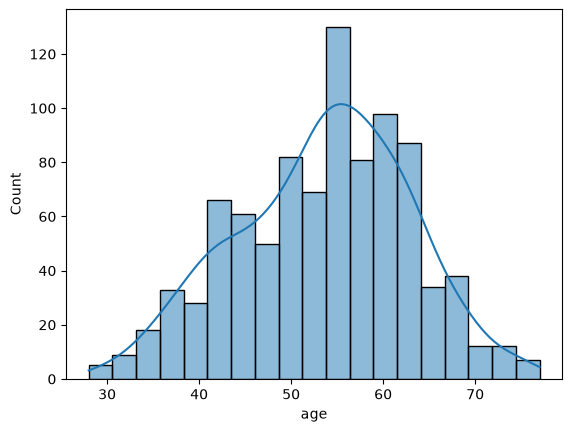

In [31]:
# draw a histogram to see distribution of age column
sns.histplot(df['age'], kde= True)

Mean: 53.51086956521739
Median: 54.0
Mode: 54


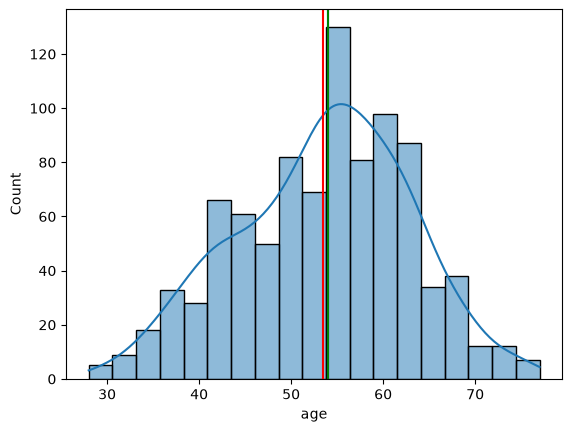

In [32]:
# plot the mean, median, mode of age column
sns.histplot(df['age'], kde=True)
plt.axvline(df['age'].mean(), color= 'red')
plt.axvline(df['age'].median(), color= 'blue')
plt.axvline(df['age'].mode()[0], color= 'green')

# print value of mean, median, mode of age column
print('Mean:', df['age'].mean())
print('Median:', df['age'].median())
print('Mode:', df['age'].mode()[0])

In [34]:
# plot the histogram of age column using plotly and coloring this by sex

fig = px.histogram(data_frame=df, x='age', color='sex')
fig.show()

In [ ]:
# find the values of sex column
df['sex'].value_counts()

sex
Male      726
Female    194
Name: count, dtype: int64

In [40]:
# calculate percentage of male and female value counts in the data
male_count= 726
female_count = 194
total_count = male_count+ female_count

# calculate percentage
male_percentage = (male_count / total_count) * 100
female_percentage = (female_count / total_count) * 100

# display results
print(f'Male percentage in data: {male_percentage: 2f}%')
print(f'female percentage in data: {female_percentage: 2f}%')

# difference
difference_percentage = ((male_count - female_count) / female_count) * 100
print(f'Males are: {difference_percentage: 2f}% more than females')

Male percentage in data:  78.913043%
female percentage in data:  21.086957%
Males are:  274.226804% more than females


In [37]:
# find the value count of age column by grouping by sex column
df.groupby('sex')['age'].value_counts()

sex     age
Female  54     15
        51     11
        62     10
        43      9
        48      9
               ..
Male    71      2
        31      1
        28      1
        33      1
        76      1
Name: count, Length: 91, dtype: int64

#### outputs:
1. The minimum age to have a heart disease starts from 28 years old.
2. Most of the people get heart disease at the age of 53-54 years.
3. Most of the males and females are with heart disease at the age of 54-55 years.